# Evaluación de la propuesta de valor — NeuraDash

Este notebook responde una pregunta distinta a «¿cuánto accuracy tiene el modelo?»:

> **¿Qué evidencia respalda cada promesa de NeuraDash?**

Las promesas son: anticipar a 8 horas, personalizar por infante, ser honesto cuando no hay datos, explicar los factores y apoyar sin diagnosticar.

> **Límite:** los datos son sintéticos. Esta evaluación valida el pipeline y la metodología, no el rendimiento clínico.

In [1]:
import sys
from pathlib import Path

import pandas as pd

# El notebook vive en notebooks/; el proyecto está un nivel arriba.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ml.data_loading import load_subject_data
from ml.evaluation import evaluate_subjects

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

SUBJECTS = ["PAC-A", "PAC-B"]
bundles = {sid: load_subject_data(sid, PROJECT_ROOT / "data") for sid in SUBJECTS}
results = evaluate_subjects(bundles)

print("Generado:", results["generated_at"])
print("Sujetos:", ", ".join(results["subjects"]))

Generado: 2026-11-08T03:57:14.263975+00:00
Sujetos: PAC-A, PAC-B


## 1. Datos y diseño

Cortes diarios, folds de ventana expansiva (`walk_forward`), sin usar el futuro para entrenar.

In [2]:
dataset_rows = []
for sid, result in results["subjects"].items():
    d = result["dataset"]
    dataset_rows.append({
        "Sujeto": sid,
        "Ejemplos": d["n_examples"],
        "Crisis": d["n_positive"],
        "Prevalencia": d["prevalence"],
        "Folds": d["n_folds"],
        "Folds usables": d["n_successful_folds"],
        "Inicio": d["cutoff_start"][:10] if d["cutoff_start"] else None,
        "Fin": d["cutoff_end"][:10] if d["cutoff_end"] else None,
    })

pd.DataFrame(dataset_rows)

,Sujeto,Ejemplos,Crisis,Prevalencia,Folds,Folds usables,Inicio,Fin
0,PAC-A,86,24,0.279070,8,8,2026-08-08,2026-11-01
1,PAC-B,86,21,0.244186,8,8,2026-08-08,2026-11-01


## 2. Promesa: anticipar

Métricas del clasificador sobre predicciones **out-of-fold** y comparación contra baselines.

La persistencia predice crisis si hubo una crisis moderada/severa en las 24 h previas al corte: es un baseline honesto y difícil de superar en datos autocorrelacionados.

In [3]:
metric_rows = []
for sid, result in results["subjects"].items():
    m = result["pooled"]["metrics"]
    metric_rows.append({
        "Sujeto": sid,
        "n": m["n"],
        "Crisis": m["positives"],
        "Prevalencia": m["prevalence"],
        "Precision@0.5": m["precision"],
        "Recall@0.5": m["recall"],
        "F1@0.5": m["f1"],
        "ROC-AUC": m["roc_auc"],
        "PR-AUC": m["pr_auc"],
        "Brier": m["brier"],
    })

pd.DataFrame(metric_rows)

,Sujeto,n,Crisis,Prevalencia,Precision@0.5,Recall@0.5,F1@0.5,ROC-AUC,PR-AUC,Brier
0,PAC-A,56,11,0.196429,0.444444,0.363636,0.40,0.717172,0.492228,0.158363
1,PAC-B,56,19,0.339286,0.500000,0.157895,0.24,0.746799,0.580027,0.262950


In [4]:
baseline_rows = []
for sid, result in results["subjects"].items():
    for name, baseline in result["baselines"].items():
        m = baseline["metrics"]
        baseline_rows.append({
            "Sujeto": sid,
            "Baseline": name,
            "Accuracy": m["accuracy"],
            "Precision": m["precision"],
            "Recall": m["recall"],
            "F1": m["f1"],
            "ROC-AUC": m["roc_auc"],
            "PR-AUC": m["pr_auc"],
        })

pd.DataFrame(baseline_rows)

,Sujeto,Baseline,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,PAC-A,majority,0.803571,0.000000,0.000000,0.000000,0.500000,0.196429
1,PAC-A,prior,0.803571,0.000000,0.000000,0.000000,0.210101,0.162338
2,PAC-A,persistence,0.767857,0.416667,0.454545,0.434783,0.649495,0.296537
3,PAC-B,majority,0.660714,0.000000,0.000000,0.000000,0.500000,0.339286
4,PAC-B,prior,0.660714,0.000000,0.000000,0.000000,0.500000,0.359264
5,PAC-B,persistence,0.660714,0.500000,0.526316,0.512821,0.628023,0.423872


### Distribución de scores

Si la media de los positivos queda por debajo del umbral de producto, el recall cae aunque el ranking sea bueno. Esta tabla ayuda a detectar ese desajuste.

In [5]:
score_rows = []
for sid, result in results["subjects"].items():
    summary = result["pooled"]["score_summary"]
    score_rows.append({
        "Sujeto": sid,
        "Mín.": summary["min"],
        "Máx.": summary["max"],
        "Media": summary["mean"],
        "Media crisis": summary["mean_positive"],
        "Media sin crisis": summary["mean_negative"],
    })

pd.DataFrame(score_rows)

,Sujeto,Mín.,Máx.,Media,Media crisis,Media sin crisis
0,PAC-A,0.000180,0.958685,0.200726,0.395425,0.153132
1,PAC-B,0.000157,0.992400,0.182642,0.275121,0.135152


## 3. Promesa: ser honesto

Métricas del **producto**, no solo del clasificador: cobertura, abstención y carga de alertas.

- `HIGH`: score por encima del umbral alto (0.7).
- `MEDIA+`: score por encima del umbral bajo (0.3).
- `recall_overall` cuenta las crisis de días abstendidos como no cubiertas.

In [6]:
product_rows = []
for sid, result in results["subjects"].items():
    p = result["pooled"]["product"]
    product_rows.append({
        "Sujeto": sid,
        "Cobertura": p["coverage"],
        "Abstención": p["abstention_rate"],
        "Alerta HIGH": p["high"]["alert_rate"],
        "Recall HIGH": p["high"]["recall_overall"],
        "FA/semana HIGH": p["high"]["false_alarms_per_week"],
        "Alerta MEDIA+": p["any"]["alert_rate"],
        "Recall MEDIA+": p["any"]["recall_overall"],
        "FA/semana MEDIA+": p["any"]["false_alarms_per_week"],
    })

pd.DataFrame(product_rows)

,Sujeto,Cobertura,Abstención,Alerta HIGH,Recall HIGH,FA/semana HIGH,Alerta MEDIA+,Recall MEDIA+,FA/semana MEDIA+
0,PAC-A,1.0,0.0,0.089286,0.272727,0.250,0.250000,0.545455,1.000
1,PAC-B,1.0,0.0,0.107143,0.157895,0.375,0.178571,0.263158,0.625


### El caso de abstención (PAC-C)

La promesa de honestidad no se ve en PAC-A/B porque tienen historial suficiente. Se ve en el arranque en frío: el sistema prefiere no estimar antes que inventar un número.

In [7]:
from datetime import timedelta
from ml.evaluation import cold_start_case

pac_c = load_subject_data("PAC-C", PROJECT_ROOT / "data")
last_record = max(record["source_timestamp"] for record in pac_c["records"])
cold = cold_start_case(
    records=pac_c["records"],
    cutoff=last_record + timedelta(days=1),
    timezone=pac_c["profile"]["timezone"],
    planned_events=pac_c["planned_events"],
)

pd.DataFrame([{
    "Sujeto": "PAC-C",
    "Días de historial": cold["baseline_maturity"],
    "Confianza": cold["confidence"],
    "Se abstiene": cold["abstain"],
    "Motivo": cold["reason"],
}])

,Sujeto,Días de historial,Confianza,Se abstiene,Motivo
0,PAC-C,2,HIGH,True,Insufficient baseline maturity (2 days). Minim...


## 4. Promesa: elegir el punto de operación

El umbral no debería ser 0.5 por inercia. Aquí se comparan el umbral actual, el mejor F1 y el máximo recall con un presupuesto de **≤1 falsa alarma por semana**.

Estos puntos son exploratorios: se calculan sobre predicciones out-of-fold y sirven para discutir el trade-off.

In [8]:
operation_rows = []
labels = {
    "current_high": "HIGH actual",
    "current_any": "MEDIA+ actual",
    "best_f1": "mejor F1",
    "recall_at_budget": "máx. recall con ≤1 FA/semana",
}
for sid, result in results["subjects"].items():
    for key, label in labels.items():
        point = result["pooled"]["operating_points"].get(key)
        if not point:
            continue
        operation_rows.append({
            "Sujeto": sid,
            "Punto": label,
            "Umbral": point["threshold"],
            "Alertas/semana": point["alerts_per_week"],
            "Recall": point["recall"],
            "Precision": point["precision"],
            "F1": point["f1"],
            "FA/semana": point["false_alarms_per_week"],
        })

pd.DataFrame(operation_rows)

,Sujeto,Punto,Umbral,Alertas/semana,Recall,Precision,F1,FA/semana
0,PAC-A,HIGH actual,0.70,0.625,0.272727,0.600000,0.375000,0.250
1,PAC-A,MEDIA+ actual,0.30,1.750,0.545455,0.428571,0.480000,1.000
2,PAC-A,mejor F1,0.30,1.750,0.545455,0.428571,0.480000,1.000
3,PAC-A,máx. recall con ≤1 FA/semana,0.30,1.750,0.545455,0.428571,0.480000,1.000
4,PAC-B,HIGH actual,0.70,0.750,0.157895,0.500000,0.240000,0.375
5,PAC-B,MEDIA+ actual,0.30,1.250,0.263158,0.500000,0.344828,0.625
6,PAC-B,mejor F1,0.05,3.500,0.789474,0.535714,0.638298,1.625
7,PAC-B,máx. recall con ≤1 FA/semana,0.25,1.375,0.315789,0.545455,0.400000,0.625


## 5. Promesa: explicar

Variables con mayor peso medio entre folds y consistencia de signo. Los coeficientes muestran asociación, no causalidad.

In [9]:
feature_rows = []
for sid, result in results["subjects"].items():
    for feature in result["coefficients"][:10]:
        feature_rows.append({
            "Sujeto": sid,
            "Variable": feature["feature"],
            "Coef. medio": feature["mean_coefficient"],
            "Desv.": feature["std"],
            "Consistencia de signo": feature["sign_consistency"],
        })

pd.DataFrame(feature_rows)

,Sujeto,Variable,Coef. medio,Desv.,Consistencia de signo
0,PAC-A,record_count_7d,-0.955351,0.027304,1.0
1,PAC-A,strategy_count_mean_3d,0.629020,0.182187,1.0
2,PAC-A,feeding_difficulty_missing_1d,-0.605320,0.093398,1.0
3,PAC-A,transition_difficulty_mean_3d,-0.591365,0.133102,1.0
4,PAC-A,day_regulation_level_num_mean_1d,-0.496816,0.074787,1.0
5,PAC-A,start_autonomy_level_delta_baseline,0.457044,0.178477,1.0
6,PAC-A,feeding_difficulty_delta_baseline,0.428302,0.117509,1.0
7,PAC-A,feeding_difficulty_mean_1d,0.419902,0.120059,1.0
8,PAC-A,planned_stressful_event_8h,0.419469,0.049257,1.0
9,PAC-A,gi_level_mean_3d,-0.413201,0.086839,1.0


## 6. Lectura de resultados

Resumen automático de los números principales. No sustituye la interpretación

In [10]:
for sid, result in results["subjects"].items():
    m = result["pooled"]["metrics"]
    p = result["pooled"]["operating_points"]["recall_at_budget"]
    print(
        f"{sid}: ROC-AUC={m['roc_auc']:.3f}; "
        f"recall={p['recall']:.1%} con {p['false_alarms_per_week']:.2f} FA/semana "
        f"(umbral {p['threshold']:.2f}); "
        f"cobertura={result['pooled']['product']['coverage']:.0%}"
    )

PAC-A: ROC-AUC=0.717; recall=54.5% con 1.00 FA/semana (umbral 0.30); cobertura=100%
PAC-B: ROC-AUC=0.747; recall=31.6% con 0.62 FA/semana (umbral 0.25); cobertura=100%


## 7. Gráficos

Las tablas describen los números; los gráficos permiten interpretar su comportamiento. Estas figuras usan pandas para ordenar los datos y matplotlib para dibujar.

In [11]:
import matplotlib.pyplot as plt

from ml.plots import (
    plot_calibration,
    plot_confusion_matrices,
    plot_feature_importance,
    plot_precision_recall_curves,
    plot_roc_curves,
    plot_score_distributions,
    plot_threshold_tradeoff,
    save_figures,
)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
})

### ROC y Precision-Recall

La curva ROC compara la capacidad de ranking; la curva Precision-Recall es más informativa cuando las crisis son poco frecuentes. Las líneas punteadas representan el baseline de persistencia.

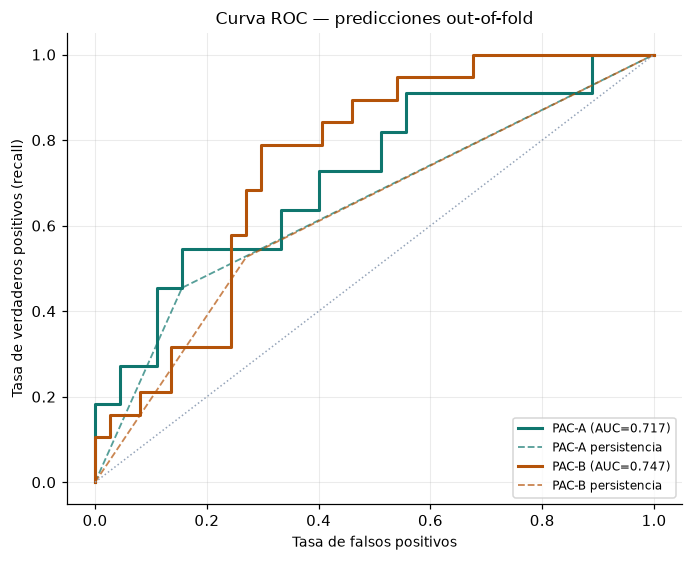

In [12]:
plot_roc_curves(results)
plt.show()

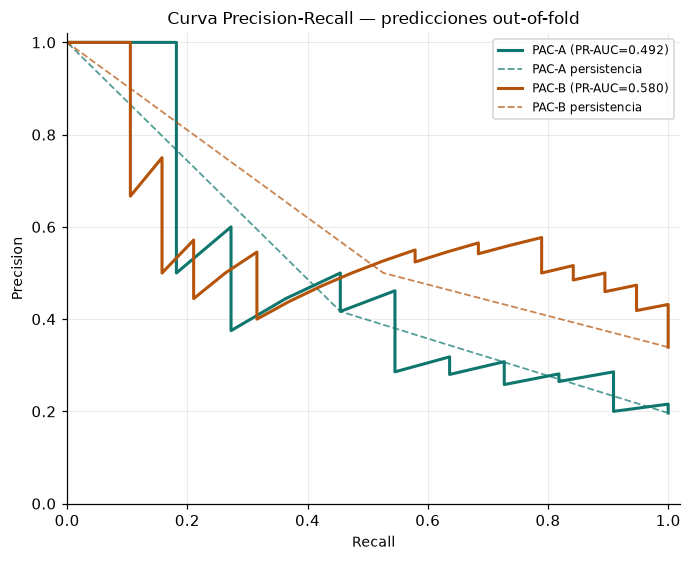

In [13]:
plot_precision_recall_curves(results)
plt.show()

### Trade-off entre recall y carga de alertas

Cada punto de la frontera corresponde a un umbral. El eje horizontal representa las falsas alarmas por semana, una medida directa de la carga para el cuidador. Las estrellas marcan el máximo recall con un presupuesto de hasta una falsa alarma por semana.

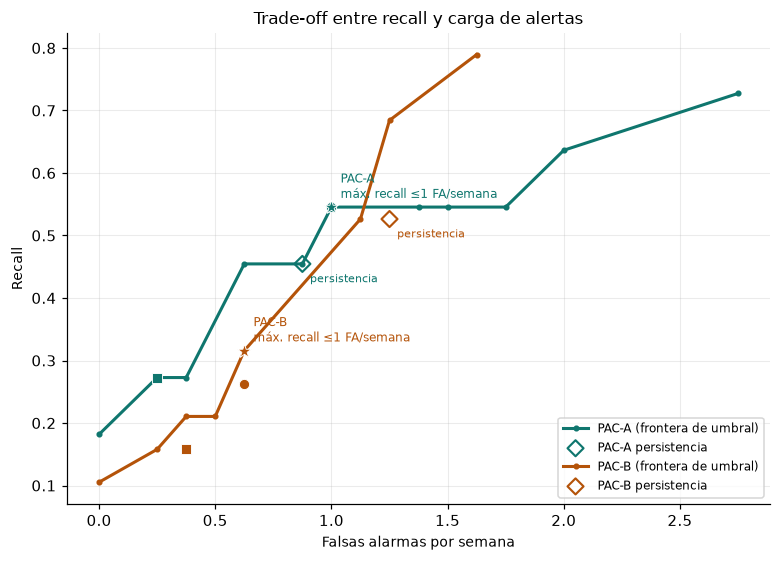

In [14]:
plot_threshold_tradeoff(results)
plt.show()

### Distribución de scores y calibración

Si los scores de los días con crisis quedan por debajo del umbral, el recall disminuye aunque el ranking sea adecuado. La curva de calibración compara el score medio con la tasa observada de crisis.

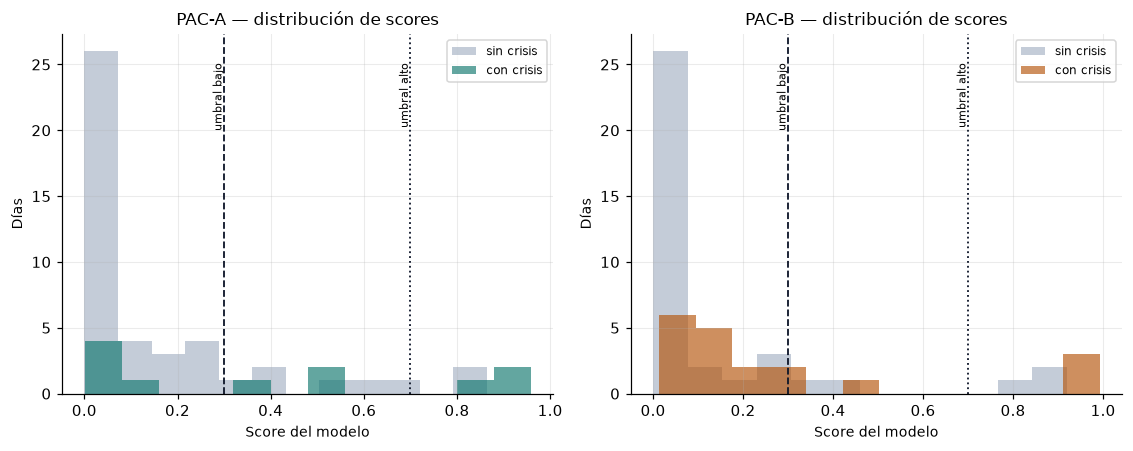

In [15]:
plot_score_distributions(results)
plt.show()

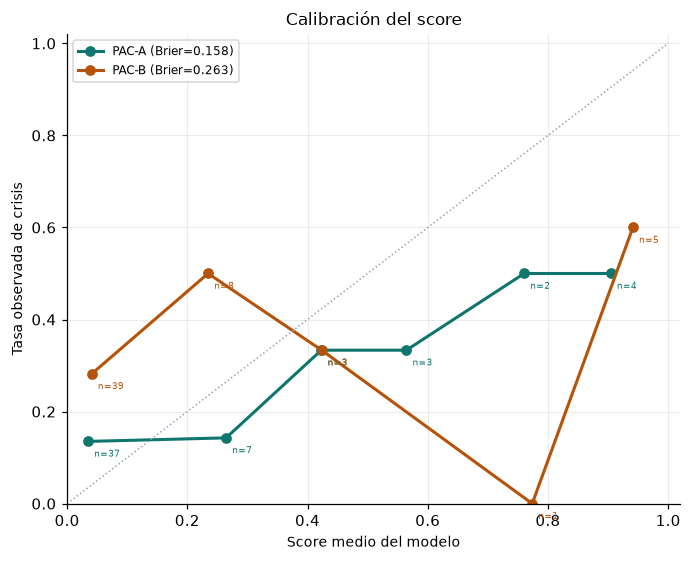

In [16]:
plot_calibration(results)
plt.show()

### Matriz de confusión y variables explicativas

La matriz utiliza el punto de operación MEDIA+ actual. Las barras muestran el coeficiente medio entre folds; la barra de error representa la desviación. Los coeficientes indican asociación, no causalidad.

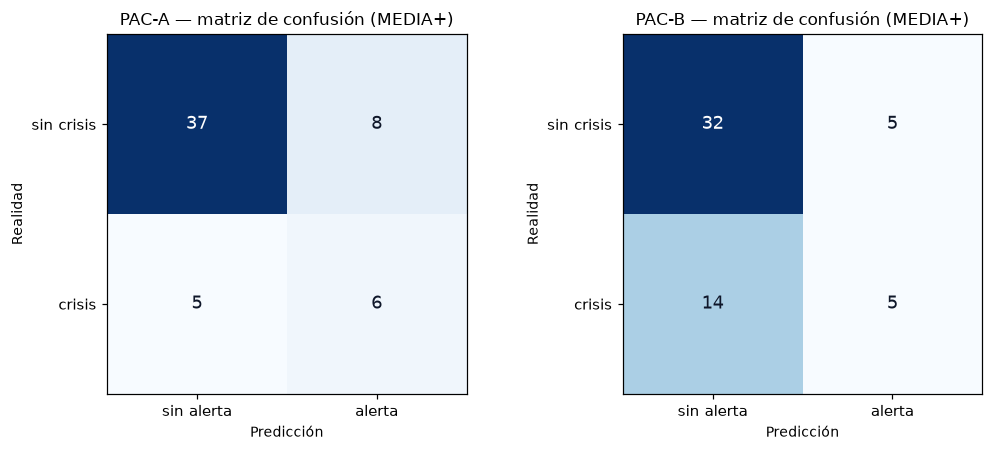

In [17]:
plot_confusion_matrices(results)
plt.show()

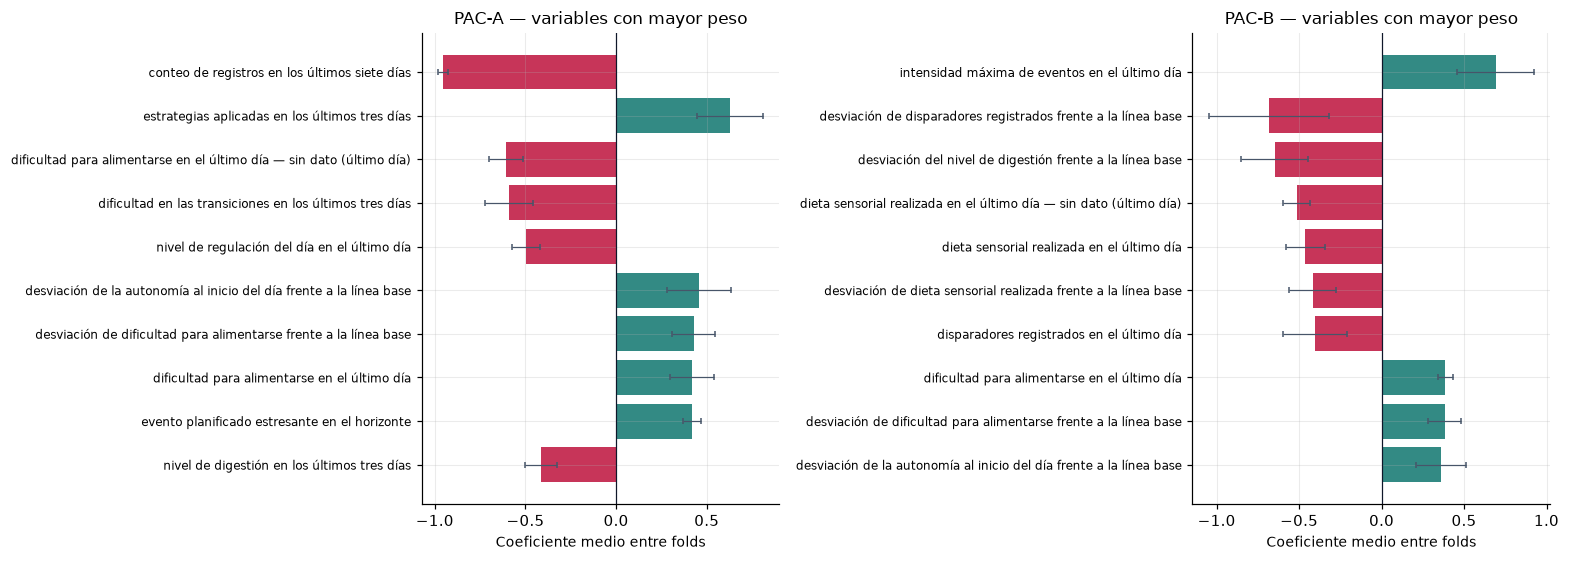

In [18]:
plot_feature_importance(results)
plt.show()

### Exportación de figuras

Las figuras se guardan en `reports/figures/` en PNG (300 dpi) y SVG (vectorial) para reutilizarlas en el informe y en material de difusión.

In [19]:
figure_paths = save_figures(results, PROJECT_ROOT / "reports" / "figures")
for path in figure_paths:
    print(path.relative_to(PROJECT_ROOT))

reports/figures/roc.png
reports/figures/roc.svg
reports/figures/precision_recall.png
reports/figures/precision_recall.svg
reports/figures/threshold_tradeoff.png
reports/figures/threshold_tradeoff.svg
reports/figures/score_distributions.png
reports/figures/score_distributions.svg
reports/figures/confusion_matrices.png
reports/figures/confusion_matrices.svg
reports/figures/feature_importance.png
reports/figures/feature_importance.svg
reports/figures/calibration.png
reports/figures/calibration.svg


## 8. Límites

- Datos sintéticos y tres perfiles demo: no hay validación clínica ni poblacional.
- El baseline de persistencia es fuerte; el modelo debe superarlo para justificar su complejidad.
- La confianza actual mide cobertura de datos (missingness), no calibración clínica del score.
- Los umbrales 0.3/0.7 son configuración del producto, no verdades clínicas.

## 9. Reproducibilidad

```bash
uv sync --extra dev --extra notebooks
uv run --extra notebooks jupyter nbconvert --execute --to html   notebooks/evaluacion_propuesta_valor.ipynb --output-dir reports
```

O desde la raíz, para regenerar las tablas:

```bash
uv run python scripts/evaluate_model.py
```
